## 1. Đọc dữ liệu

In [1]:
# %pip install pandas numpy matplotlib lightgbm scikit-learn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMRegressor
from matplotlib.patches import Patch
from sklearn.metrics import mean_absolute_error, mean_squared_error

raw = pd.read_csv("PRSA_data_2010.1.1-2014.12.31.csv")
print("Kích thước dữ liệu:", raw.shape)
display(raw.head())
display(raw.isna().sum().to_frame("Số giá trị thiếu"))

Kích thước dữ liệu: (43824, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


,Số giá trị thiếu
No,0
year,0
month,0
day,0
hour,0
pm2.5,2067
DEWP,0
TEMP,0
PRES,0
cbwd,0


## 2. Tạo thời gian UTC và chọn dữ liệu

In [2]:
time = pd.to_datetime(raw[["year", "month", "day", "hour"]])
time = time.dt.tz_localize("Asia/Shanghai").dt.tz_convert("UTC")
df = pd.DataFrame(
    {
        "timestamp": time,
        "pm25": raw["pm2.5"],
        "temp": raw["TEMP"],
        "cum_wind_speed": raw["Iws"],
        "cum_rain_hours": raw["Ir"],
    }
)
assert not df["timestamp"].duplicated().any()
rows_before = len(df)
df = df.set_index("timestamp").sort_index().asfreq("h")
print("Số giờ được thêm:", len(df) - rows_before)
print("Số giờ thiếu PM2.5:", df["pm25"].isna().sum())
display(df.head())

Số giờ được thêm: 0
Số giờ thiếu PM2.5: 2067


,pm25,temp,cum_wind_speed,cum_rain_hours
timestamp,,,,
2009-12-31 16:00:00+00:00,NaN,-11.0,1.79,0
2009-12-31 17:00:00+00:00,NaN,-12.0,4.92,0
2009-12-31 18:00:00+00:00,NaN,-11.0,6.71,0
2009-12-31 19:00:00+00:00,NaN,-14.0,9.84,0
2009-12-31 20:00:00+00:00,NaN,-12.0,12.97,0


## 3. Tạo lag và nhãn

In [3]:
local_time = df.index.tz_convert("Asia/Shanghai")
df["hour"] = local_time.hour
df["month"] = local_time.month
df["dayofweek"] = local_time.dayofweek
for lag in [1, 2, 3, 6, 12, 24]:
    df[f"pm25_lag{lag}"] = df.pm25.shift(lag)
weather = ["temp", "cum_wind_speed", "cum_rain_hours"]
for col in weather:
    for lag in [1, 3]:
        df[f"{col}_lag{lag}"] = df[col].shift(lag)
df["target"] = df.pm25.shift(-1)
df["target_time"] = df.index + pd.Timedelta(hours=1)
features_base = [
    "pm25",
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag6",
    "pm25_lag12",
    "pm25_lag24",
    "hour",
    "month",
    "dayofweek",
]
weather_features = weather + [f"{col}_lag{lag}" for col in weather for lag in [1, 3]]
features = features_base + weather_features

## 4. Xử lý thiếu

In [4]:
missing_current = df["pm25"].isna()
missing_target = df["target"].isna()
print("Thiếu PM2.5 hiện tại:", missing_current.sum())
print("Có PM2.5 hiện tại nhưng thiếu nhãn:", ((~missing_current) & missing_target).sum())
data = df.dropna(subset=["pm25", "target"]).copy()
print("Tổng số dòng bị loại:", len(df) - len(data))
print("Số dòng còn lại:", len(data))
display(data[features].isna().sum().to_frame("NaN đầu vào còn lại"))

Thiếu PM2.5 hiện tại: 2067
Có PM2.5 hiện tại nhưng thiếu nhãn: 214
Tổng số dòng bị loại: 2281
Số dòng còn lại: 41543


,NaN đầu vào còn lại
pm25,0
pm25_lag1,195
pm25_lag2,278
pm25_lag3,334
pm25_lag6,482
pm25_lag12,704
pm25_lag24,1020
hour,0
month,0
dayofweek,0


## 5. Chia train/test

In [5]:
cutoff = pd.Timestamp("2014-01-01", tz="Asia/Shanghai")
end = pd.Timestamp("2015-01-01", tz="Asia/Shanghai")
train = data[data.target_time < cutoff]
test = data[(data.target_time >= cutoff) & (data.target_time < end)]
assert train.target_time.max() < test.target_time.min()

print("Số mẫu train:", len(train))
print("Số mẫu test:", len(test))
print("Nhãn train cuối:", train.target_time.max().tz_convert("Asia/Shanghai"))
print("Nhãn test đầu:", test.target_time.min().tz_convert("Asia/Shanghai"))

Số mẫu train: 32917
Số mẫu test: 8626
Nhãn train cuối: 2013-12-31 23:00:00+08:00
Nhãn test đầu: 2014-01-01 00:00:00+08:00


## 6. Huấn luyện và dự báo

In [6]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    n_jobs=2,
    verbosity=-1,
)
model.fit(train[features], train.target)
pred = pd.DataFrame(
    {
        "target_time": test.target_time,
        "actual": test.target,
        "Persistence": test.pm25,
        "LightGBM": np.maximum(model.predict(test[features]), 0),
    }
)
assert pred.notna().all().all()

display(pred.head())

imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
display(imp.to_frame("Độ quan trọng (split)"))

,target_time,actual,Persistence,LightGBM
timestamp,,,,
2013-12-31 15:00:00+00:00,2013-12-31 16:00:00+00:00,24.0,23.0,24.576692
2013-12-31 16:00:00+00:00,2013-12-31 17:00:00+00:00,53.0,24.0,24.122240
2013-12-31 17:00:00+00:00,2013-12-31 18:00:00+00:00,65.0,53.0,53.308788
2013-12-31 18:00:00+00:00,2013-12-31 19:00:00+00:00,70.0,65.0,65.400272
2013-12-31 19:00:00+00:00,2013-12-31 20:00:00+00:00,79.0,70.0,68.541600


,Độ quan trọng (split)
pm25,1082
pm25_lag1,532
pm25_lag3,321
pm25_lag2,311
hour,289
cum_wind_speed,245
pm25_lag12,229
pm25_lag24,188
pm25_lag6,181
temp,131


## 7. MAE và RMSE

In [7]:
rows = []
for name in ["Persistence", "LightGBM"]:
    rows.append(
        {
            "Model": name,
            "MAE": mean_absolute_error(pred.actual, pred[name]),
            "RMSE": np.sqrt(mean_squared_error(pred.actual, pred[name])),
        }
    )
results = pd.DataFrame(rows).set_index("Model")

display(results.round(3))
improvement = (1 - results.loc["LightGBM"] / results.loc["Persistence"]) * 100
print("Giảm MAE (%):", round(improvement["MAE"], 2))
print("Giảm RMSE (%):", round(improvement["RMSE"], 2))

Giảm MAE (%): 3.03
Giảm RMSE (%): 4.67


,MAE,RMSE
Model,,
Persistence,11.925,22.061
LightGBM,11.564,21.030


## 8. Sai số theo tháng

In [8]:
pred["month"] = pred.target_time.dt.tz_convert("Asia/Shanghai").dt.month
rows = []
for month, group in pred.groupby("month"):
    for name in ["Persistence", "LightGBM"]:
        rows.append(
            {
                "Month": month,
                "Model": name,
                "N": len(group),
                "MAE": mean_absolute_error(group.actual, group[name]),
                "RMSE": np.sqrt(mean_squared_error(group.actual, group[name])),
            }
        )
monthly = pd.DataFrame(rows)

display(monthly.round(3))
coverage = pred.groupby("month").size().to_frame("Số mẫu")
coverage["Số giờ tháng"] = [
    pd.Timestamp(2014, int(m), 1).days_in_month * 24 for m in coverage.index
]
coverage["Độ phủ (%)"] = coverage["Số mẫu"] / coverage["Số giờ tháng"] * 100
display(coverage.round(2))

,Month,Model,N,MAE,RMSE
0,1,Persistence,735,17.322,33.037
1,1,LightGBM,735,16.400,31.759
2,2,Persistence,666,14.411,25.288
3,2,LightGBM,666,15.399,25.292
4,3,Persistence,742,12.650,22.151
5,3,LightGBM,742,12.146,20.568
6,4,Persistence,715,12.585,29.001
7,4,LightGBM,715,11.977,27.950
8,5,Persistence,741,10.762,20.031
9,5,LightGBM,741,10.621,18.801


,Số mẫu,Số giờ tháng,Độ phủ (%)
month,,,
1,735,744,98.79
2,666,672,99.11
3,742,744,99.73
4,715,720,99.31
5,741,744,99.60
6,695,720,96.53
7,735,744,98.79
8,731,744,98.25
9,710,720,98.61


## 9. Biểu đồ đường và cột

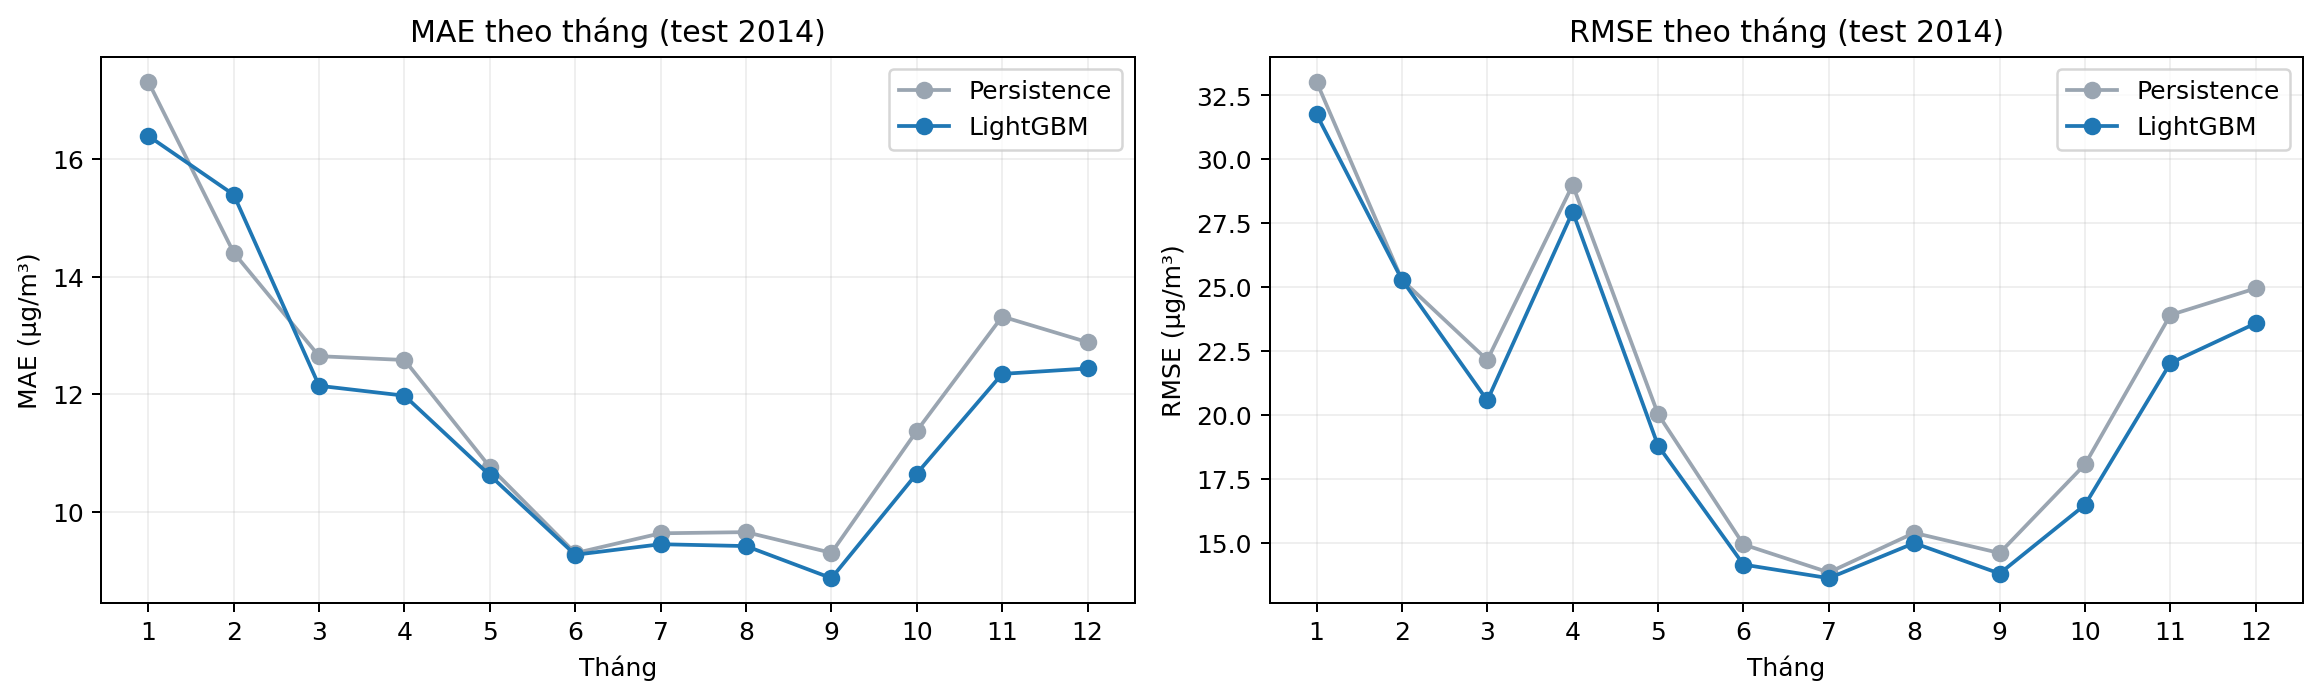

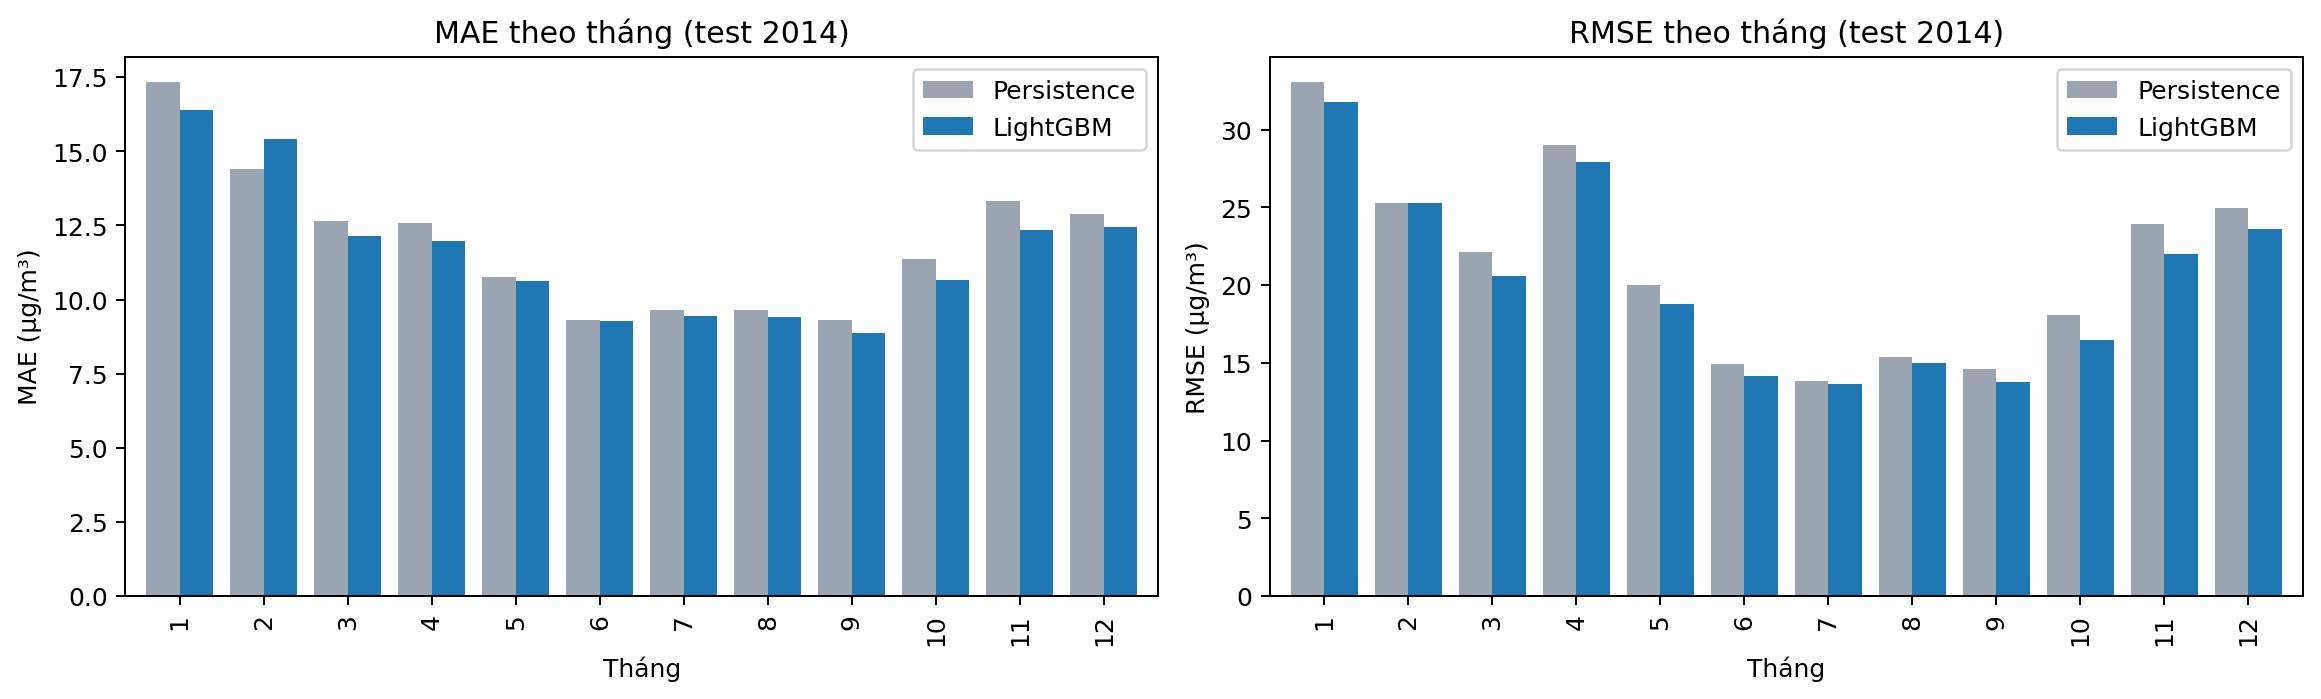

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = monthly.pivot(index="Month", columns="Model", values=metric)
    table[["Persistence", "LightGBM"]].plot(ax=ax, marker="o", color=["#9aa5b1", "#1f77b4"])
    ax.set_title(f"{metric} theo tháng (test 2014)")
    ax.set_xlabel("Tháng")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.set_xticks(range(1, 13))
    ax.legend(["Persistence", "LightGBM"])
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("error_by_month_line.png", dpi=180, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    table = monthly.pivot(index="Month", columns="Model", values=metric)
    table[["Persistence", "LightGBM"]].plot.bar(ax=ax, color=["#9aa5b1", "#1f77b4"], width=0.8)
    ax.set_title(f"{metric} theo tháng (test 2014)")
    ax.set_xlabel("Tháng")
    ax.set_ylabel(f"{metric} (µg/m³)")
    ax.legend(["Persistence", "LightGBM"])
    ax.grid(False)
plt.tight_layout()
plt.savefig("error_by_month.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Đóng góp đặc trưng

,Đóng góp (%)
Khí tượng,8.8
PM2.5 và lag,88.0
Thời gian,3.2


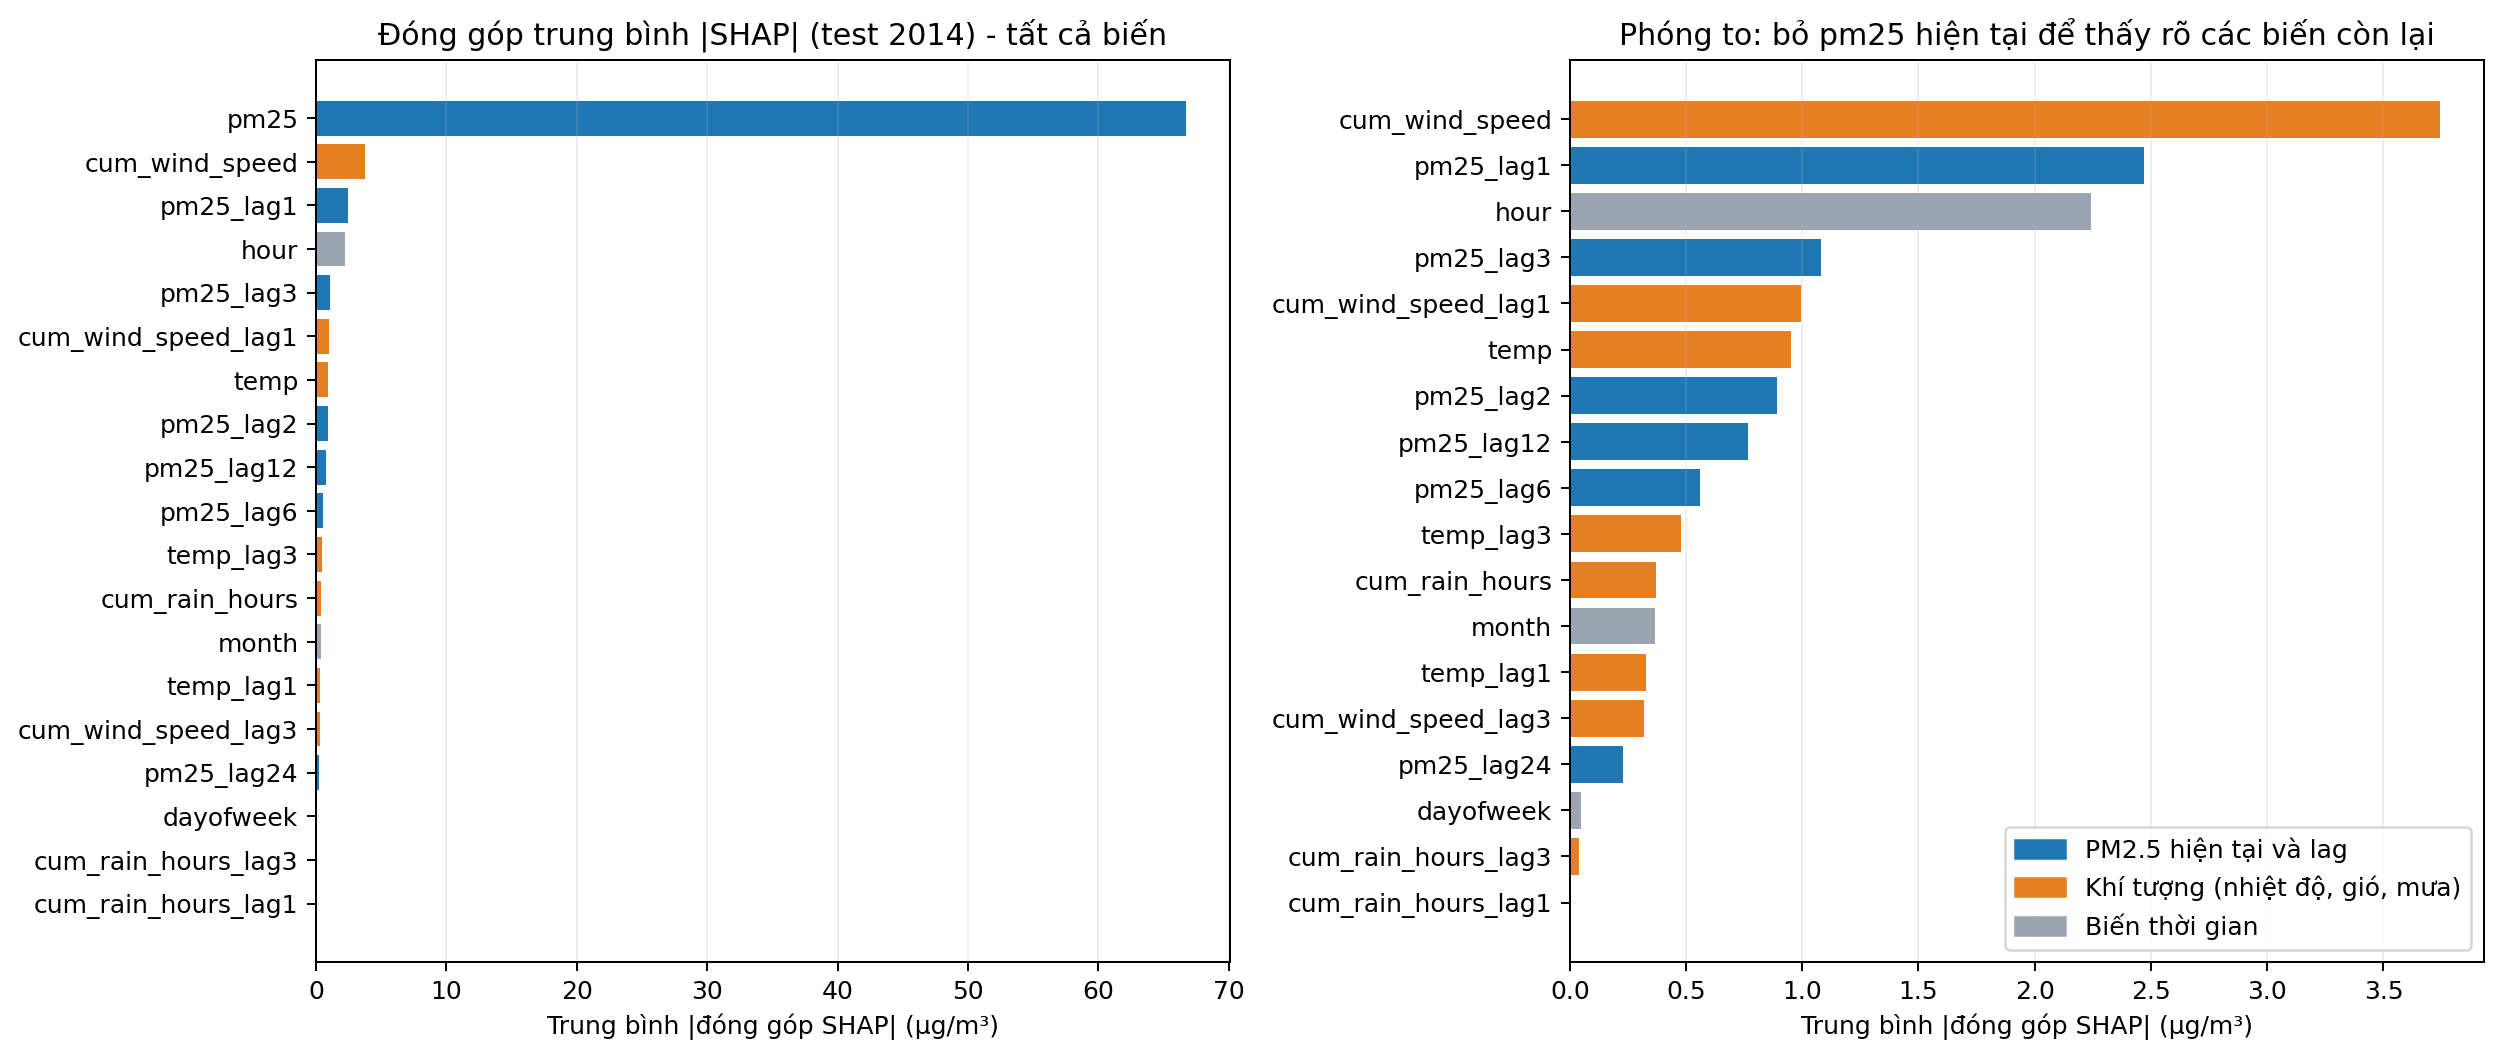

In [10]:
contrib = model.booster_.predict(test[features], pred_contrib=True)[:, :-1]
contrib = pd.DataFrame(contrib, index=test.index, columns=features)
mean_abs = contrib.abs().mean().sort_values()


def group_color(f):
    if f in weather_features:
        return "#e67e22"
    if f in ["hour", "month", "dayofweek"]:
        return "#9aa5b1"
    return "#1f77b4"


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(mean_abs.index, mean_abs.values, color=[group_color(f) for f in mean_abs.index])
axes[0].set_title("Đóng góp trung bình |SHAP| (test 2014) - tất cả biến")
zoom = mean_abs.drop("pm25")
axes[1].barh(zoom.index, zoom.values, color=[group_color(f) for f in zoom.index])
axes[1].set_title("Phóng to: bỏ pm25 hiện tại để thấy rõ các biến còn lại")
for ax in axes:
    ax.set_xlabel("Trung bình |đóng góp SHAP| (µg/m³)")
    ax.grid(axis="x", alpha=0.2)

axes[1].legend(
    handles=[
        Patch(color="#1f77b4", label="PM2.5 hiện tại và lag"),
        Patch(color="#e67e22", label="Khí tượng (nhiệt độ, gió, mưa)"),
        Patch(color="#9aa5b1", label="Biến thời gian"),
    ],
    loc="lower right",
)
plt.tight_layout()
plt.savefig("feature_contribution.png", dpi=180, bbox_inches="tight")
plt.show()

group = pd.Series(
    {
        f: "Khí tượng"
        if f in weather_features
        else "Thời gian"
        if f in ["hour", "month", "dayofweek"]
        else "PM2.5 và lag"
        for f in features
    }
)
display(
    (contrib.abs().mean().groupby(group).sum() / contrib.abs().mean().sum() * 100)
    .round(1)
    .to_frame("Đóng góp (%)")
)